# iTF alıştırması: FOOOF ile bireysel teta frekansı

Bu notebook'ta konuştuğumuz iki grafiği kendin üreteceksin:

1. **Ham spektrum** (yokuşlu hali): teta tepesi görünmüyor.
2. **Yokuş çıkarılmış spektrum** (FOOOF / specparam): teta tümseği ortaya çıkıyor, iTF = tümseğin tepesi.

Gerçek EEG yerine önce **sahte bir EEG** üretiyoruz. Avantajı: içine 6 Hz'lik bir teta koyduğumuz için doğru cevabı biliyoruz. Yöntemin bu cevabı bulup bulmadığını kontrol edebiliriz.

Her hücreyi sırayla çalıştır: hücreye tıkla, `Shift + Enter`.

## 1. Paketleri yükle

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from specparam import SpectralModel

print("Her şey hazır!")

Matplotlib is building the font cache; this may take a moment.


Her şey hazır!


## 2. Sahte EEG üret

Sinyal üç parçanın toplamı:

- **1/f arka plan** (yokuş): gerçek EEG'deki gibi, düşük frekansta güçlü, yüksek frekansta zayıf gürültü
- **Teta** (6 Hz): zayıf, bizim bulmak istediğimiz ritim
- **Alfa** (10 Hz): güçlü, yaşlılarda da genelde net görünen ritim

`THETA_HZ` değerini değiştirerek farklı bir "kişi" yaratabilirsin.

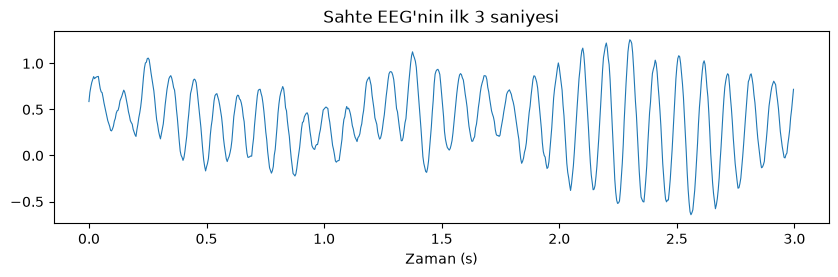

In [2]:
THETA_HZ = 6.0     # bu kişinin gerçek teta frekansı (cevap anahtarı)
ALPHA_HZ = 10.0    # bu kişinin alfa frekansı
fs = 250           # örnekleme hızı (Hz)
dakika = 2         # kayıt süresi

rng = np.random.default_rng(seed=1)
n = fs * 60 * dakika
t = np.arange(n) / fs

def dar_bant_gurultu(merkez, genislik):
    # Belirli bir frekans etrafında salınan, gerçekçi (biraz düzensiz) bir ritim
    spektrum = rng.normal(size=n // 2 + 1) + 1j * rng.normal(size=n // 2 + 1)
    f = np.fft.rfftfreq(n, 1 / fs)
    spektrum *= np.exp(-((f - merkez) ** 2) / (2 * genislik ** 2))
    s = np.fft.irfft(spektrum, n)
    return s / s.std()

# 1/f arka plan (yokuş)
spektrum = rng.normal(size=n // 2 + 1) + 1j * rng.normal(size=n // 2 + 1)
f = np.fft.rfftfreq(n, 1 / fs)
f[0] = 1
arka_plan = np.fft.irfft(spektrum / f ** 1.0, n)
arka_plan /= arka_plan.std()

teta = 0.03 * dar_bant_gurultu(THETA_HZ, 1.5)
alfa = 0.30 * dar_bant_gurultu(ALPHA_HZ, 0.8)
eeg = arka_plan + teta + alfa

plt.figure(figsize=(10, 2.5))
plt.plot(t[: 3 * fs], eeg[: 3 * fs], lw=0.8)
plt.xlabel("Zaman (s)")
plt.title("Sahte EEG'nin ilk 3 saniyesi")
plt.show()

## 3. Grafik 1: ham spektrum

Welch yöntemiyle her frekansta ne kadar güç olduğunu hesaplıyoruz (4 saniyelik pencereler, Alexander 2006'daki gibi). Gri alan teta bandı (4–8 Hz).

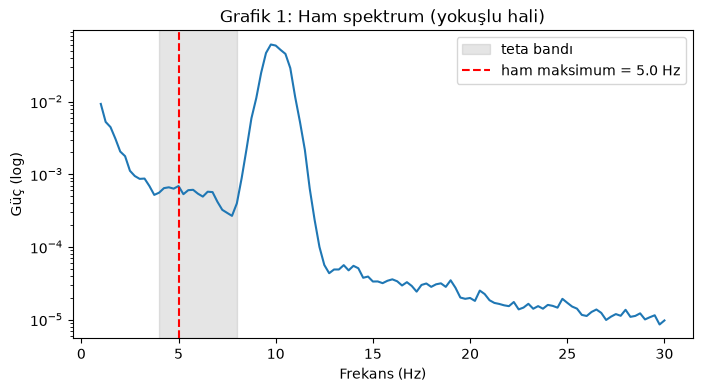

Teta bandındaki ham maksimum: 5.0 Hz
Gerçek teta (cevap anahtarı): 6.0 Hz


In [3]:
frekans, guc = welch(eeg, fs=fs, nperseg=4 * fs)

aralik = (frekans >= 1) & (frekans <= 30)
teta_bandi = (frekans >= 4) & (frekans <= 8)
ham_maks = frekans[teta_bandi][np.argmax(guc[teta_bandi])]

plt.figure(figsize=(8, 4))
plt.semilogy(frekans[aralik], guc[aralik])
plt.axvspan(4, 8, color="gray", alpha=0.2, label="teta bandı")
plt.axvline(ham_maks, color="red", ls="--", label=f"ham maksimum = {ham_maks:.1f} Hz")
plt.xlabel("Frekans (Hz)")
plt.ylabel("Güç (log)")
plt.title("Grafik 1: Ham spektrum (yokuşlu hali)")
plt.legend()
plt.show()

print(f"Teta bandındaki ham maksimum: {ham_maks:.1f} Hz")
print(f"Gerçek teta (cevap anahtarı): {THETA_HZ:.1f} Hz")

**Dikkat et:** Ham maksimum gerçek değerden (6 Hz) daha düşük çıktı. Sebebi yokuş: spektrum soldan sağa düştüğü için teta tümseğinin sol tarafı, yokuşun katkısıyla olduğundan yüksek görünüyor ve tepe sola kayıyor. Yani **ham maksimum ≠ iTF.**

## 4. FOOOF: yokuşu çıkar

`SpectralModel` spektruma bir 1/f çizgisi (yokuş) oturtur, onu çıkarır ve kalan tümsekleri bulur.

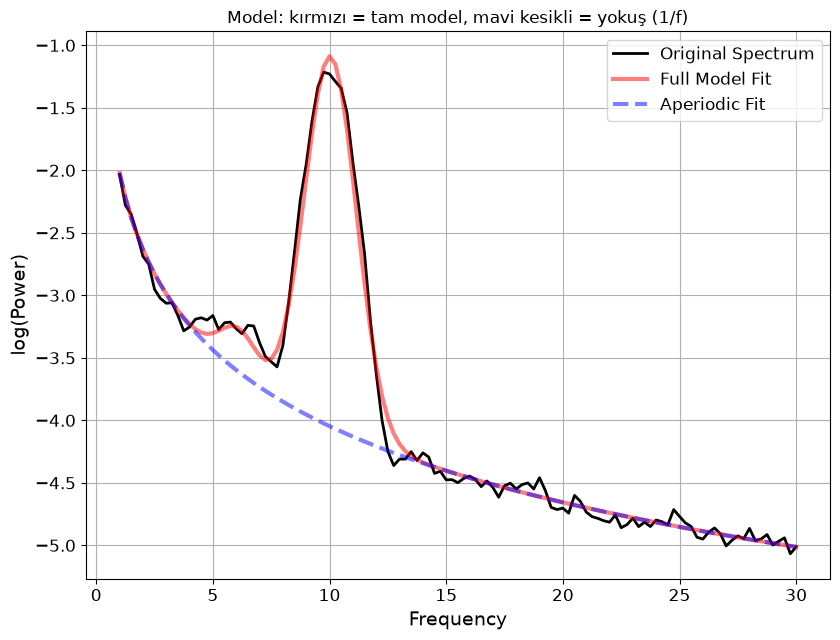

Uyum kalitesi (R²): 0.994
Yokuşun üssü (exponent): 2.02


In [4]:
model = SpectralModel(
    peak_width_limits=[1, 8],   # bir tümseğin genişliği 1 ile 8 Hz arası olabilir
    max_n_peaks=4,              # en fazla 4 tümsek ara
    min_peak_height=0.1,        # çok küçük tümsekleri sayma
    aperiodic_mode="fixed",     # düz bir yokuş çizgisi
    verbose=False,
)
model.fit(frekans, guc, [1, 30])

model.plot()
plt.title("Model: kırmızı = tam model, mavi kesikli = yokuş (1/f)")
plt.show()

print("Uyum kalitesi (R²):", round(model.get_metrics("gof"), 3))
print("Yokuşun üssü (exponent):", round(model.get_params("aperiodic")[-1], 2))

## 5. Grafik 2: yokuş çıkarılmış spektrum ve iTF

Her frekansta *ölçülen eksi yokuş* hesaplanıyor. Kalan tümseklerin tepesi bize iTF'yi ve IAF'yi veriyor.

Bulunan tümsekler (merkez Hz, yükseklik, genişlik):
[[ 6.1   0.35  1.6 ]
 [10.05  2.96  2.22]]


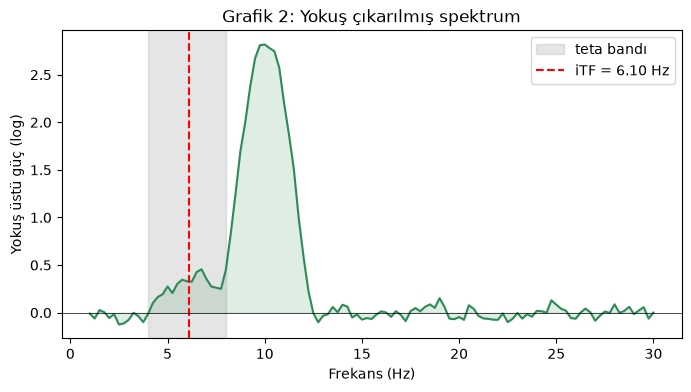

In [5]:
tepeler = model.get_params("periodic")   # her satır: [merkez frekans, yükseklik, genişlik]
tepeler = np.atleast_2d(tepeler)
print("Bulunan tümsekler (merkez Hz, yükseklik, genişlik):")
print(np.round(tepeler, 2))

def banttaki_tepe(tepeler, alt, ust):
    # Banttaki en yüksek tümseğin merkez frekansı; yoksa NaN
    secili = [p for p in tepeler if alt <= p[0] <= ust]
    if not secili:
        return np.nan
    return max(secili, key=lambda p: p[1])[0]

itf = banttaki_tepe(tepeler, 4, 8)
iaf = banttaki_tepe(tepeler, 8, 13)

# Yokuş çıkarılmış spektrum (log ölçekte: ölçülen - yokuş)
frek_model = model.data.freqs
duz = model.data.power_spectrum - model.results.model._ap_fit

plt.figure(figsize=(8, 4))
plt.plot(frek_model, duz, color="seagreen")
plt.fill_between(frek_model, duz, 0, color="seagreen", alpha=0.15)
plt.axvspan(4, 8, color="gray", alpha=0.2, label="teta bandı")
if not np.isnan(itf):
    plt.axvline(itf, color="red", ls="--", label=f"iTF = {itf:.2f} Hz")
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("Frekans (Hz)")
plt.ylabel("Yokuş üstü güç (log)")
plt.title("Grafik 2: Yokuş çıkarılmış spektrum")
plt.legend()
plt.show()

## 6. Sonuçları karşılaştır

In [6]:
print(f"Gerçek teta (cevap anahtarı):  {THETA_HZ:.2f} Hz")
print(f"Ham maksimum (yanlış yöntem):  {ham_maks:.2f} Hz")
print(f"FOOOF iTF (doğru yöntem):      {itf:.2f} Hz")
print()
print(f"IAF (alfa tepesi):             {iaf:.2f} Hz")
print(f"Yedek plan, IAF ÷ 2:           {iaf / 2:.2f} Hz   (harmonik)")
print(f"Yedek plan, IAF ÷ 1.618:       {iaf / 1.618:.2f} Hz   (altın oran)")

Gerçek teta (cevap anahtarı):  6.00 Hz
Ham maksimum (yanlış yöntem):  5.00 Hz
FOOOF iTF (doğru yöntem):      6.10 Hz

IAF (alfa tepesi):             10.05 Hz
Yedek plan, IAF ÷ 2:           5.03 Hz   (harmonik)
Yedek plan, IAF ÷ 1.618:       6.21 Hz   (altın oran)


## 7. Kendin dene

1. 2. hücrede `THETA_HZ = 5.0` yap ve bütün hücreleri yeniden çalıştır (üstteki **Run All**). FOOOF yine doğru buluyor mu?
2. `teta = 0.03 * ...` satırındaki `0.03`'ü `0.005` yap (çok zayıf teta). FOOOF hâlâ tümsek buluyor mu? Bulamazsa iTF `nan` çıkar: işte "teta tümseği yoksa ne yaparız?" sorusunun pratikteki hali.
3. `ALPHA_HZ`'yi değiştir ve yedek plan sonuçlarının nasıl değiştiğine bak.